# Anonimización de datos y responsabilidad ética en su uso

Cuando trabajamos con datos de personas (clientes, contribuyentes, pacientes, empleados) tenemos una doble obligación: **aprovechar la información** y **proteger a las personas** a las que pertenece. Anonimizar es transformar los datos para que ya no se pueda saber a quién corresponde cada registro.

En esta notebook vamos a:

| Parte | Tema |
|---|---|
| Ejercicios 1 y 2 | Reemplazar datos identificatorios con la librería `anonymizedf` |
| Ejercicio 3 | Por qué cambiar el nombre **no alcanza**: reidentificación y k-anonimato |
| Ejercicio 4 | Seudonimización contra anonimización, y el equilibrio entre privacidad y utilidad |
| Cierre | Responsabilidad ética y marco legal en el uso de datos |

### Tres tipos de datos en un registro

| Tipo | Qué es | Ejemplos |
|---|---|---|
| **Identificadores directos** | Identifican por sí solos a una persona | Nombre, DNI, CUIT, correo, número de cliente |
| **Cuasi-identificadores** | No identifican solos, pero **combinados** sí | Edad, sexo, código postal, profesión, fecha de nacimiento |
| **Atributos sensibles** | Lo que queremos proteger | Salud, ingresos, deudas, religión, afiliación política |

Anonimizar no es solo borrar el nombre: hay que cortar el camino de los cuasi-identificadores hacia la persona.

In [ ]:
#instalamos el módulo que utilizaremos (1 vez)
!pip install anonymizedf --quiet

In [ ]:
#cargamos las librerias necesarias
import pandas as pd #para manejo de archivos
from anonymizedf.anonymizedf import anonymize #para anonimizar los datos

---
# Ejercicio 1 · Anonimizar identificadores con `anonymizedf`

Usamos los datos de los pasajeros del Titanic: 891 personas con nombre, edad, sexo, clase, tarifa y si sobrevivieron.

`anonymizedf` **agrega** columnas nuevas con el prefijo `Fake_` y deja las originales, para que podamos comparar. Al final hay que quedarse solo con las columnas anonimizadas.

In [ ]:
# Importamos el conjunto de datos
!wget -q -O titanic.csv https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv

In [ ]:
#leemos el archivo importado y generamos el DataFrame
archivo_1=pd.read_csv('titanic.csv')
#Lo vemos
archivo_1

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
# Preparamos el conjunto de datos para ser anonimizado
# Aquí se genera un objeto "an" de la clase anonymize,
#Este paso prepara el DataFrame para aplicar las funciones de anonimización de la librería anonymizedf.
an = anonymize(archivo_1)

# Seleccionamos las columnas que deseamos anonimizar
an.fake_names("Name")
an.fake_ids("PassengerId")
#se generarán nombres falsos y se asignará a los nombres originales.
#si hay nombres idénticos en la columna original,se les asignará el mismo nombre falso
#para mantener la consistencia en el conjunto de datos anonimizado.
archivo_1

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Fake_Name,Fake_PassengerId
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Stuart Walsh,TRTL69583657698036
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mitchell Smith,WJSB30878046517779
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Sheila Parker,KKYB79303282243783
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Ricky Moss,KEIN84204520958741
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Gillian Taylor,WZHG15123895143208
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Dr Dominic John,TCHI88108099305296
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Miss Sarah Clark,PKGF11569825874317
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,Raymond North-Atkinson,TKHL47894271142968
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Elliot Edwards,ZFUC00019440774451


In [ ]:
an.fake_decimal_numbers("Fare")
#Anonimiza columnas que contienen números decimales (como salarios, precios, mediciones).
#Sustituye los números decimales originales por números decimales falsos,
#manteniendo la coherencia para los valores repetidos.
archivo_1

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Fake_Name,Fake_PassengerId,Fake_Fare
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Stuart Walsh,TRTL69583657698036,239.31
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mitchell Smith,WJSB30878046517779,340.85
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Sheila Parker,KKYB79303282243783,160.64
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Ricky Moss,KEIN84204520958741,278.25
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Gillian Taylor,WZHG15123895143208,339.85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Dr Dominic John,TCHI88108099305296,152.28
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Miss Sarah Clark,PKGF11569825874317,398.28
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,Raymond North-Atkinson,TKHL47894271142968,350.00
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Elliot Edwards,ZFUC00019440774451,398.28


### Otras funciones de la librería

| Función | Para qué tipo de columna | Qué hace |
|---|---|---|
| `fake_names()` | Nombres | Nombres inventados |
| `fake_ids()` | Identificadores | Códigos alfanuméricos al azar |
| `fake_whole_numbers()` | Números enteros | Enteros al azar |
| `fake_decimal_numbers()` | Números con decimales | Decimales al azar |
| `fake_categories()` | Categorías | Etiquetas genéricas ("Segment 1", "Segment 2"…) |
| `fake_dates()` | Fechas | Fechas al azar |

En todos los casos, **un mismo valor original recibe siempre el mismo valor falso**. Así se conservan las relaciones dentro de la tabla (por ejemplo, todas las compras de un mismo cliente siguen juntas).

### Probemos qué ocurre cuando en dos registros tenemos el mismo dato

In [ ]:
archivo_1.loc[0,"Name"]="Pepe Rodriguez"
archivo_1.loc[1,"Name"]="Pepe Rodriguez"

an = anonymize(archivo_1)
an.fake_names("Name")
an.fake_decimal_numbers("Fare")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Fake_Name,Fake_PassengerId,Fake_Fare
0,1,0,3,Pepe Rodriguez,male,22.0,1,0,A/5 21171,7.2500,NaN,S,Dr Sam Rowley,TRTL69583657698036,207.00
1,2,1,1,Pepe Rodriguez,female,38.0,1,0,PC 17599,71.2833,C85,C,Dr Sam Rowley,WJSB30878046517779,80.38
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Victoria Wood,KKYB79303282243783,278.95
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Sophie Clarke,KEIN84204520958741,82.48
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mrs Zoe Scott,WZHG15123895143208,396.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Mr Harry Holmes,TCHI88108099305296,83.84
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Lydia Pearce-Pearson,PKGF11569825874317,23.43
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,Dr Duncan Murray,TKHL47894271142968,434.78
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Dorothy Hewitt,ZFUC00019440774451,23.43


Los dos registros de "Pepe Rodriguez" reciben el **mismo** nombre falso: la librería mantiene la consistencia.

**Ojo con un detalle.** Fíjense en `Fake_Fare`: la tarifa falsa es un número al azar que **no conserva ninguna relación** con la tarifa real. Un pasajero de primera clase puede quedar con una tarifa menor que uno de tercera. Vamos a volver sobre esto en el ejercicio 4.

### Qué conservar y qué publicar

El DataFrame completo, con columnas originales y falsas, es la **tabla de correspondencia**: permite volver de los datos falsos a las personas. Hay que guardarla en un lugar seguro, con acceso restringido, o directamente eliminarla. Lo que se publica o se comparte es un conjunto nuevo **solo con las columnas anonimizadas y las de interés**.

In [ ]:
# Tabla de correspondencia: queda guardada aparte y con acceso restringido (o se elimina)
correspondencia = archivo_1[["PassengerId", "Fake_PassengerId", "Name", "Fake_Name"]]

# Conjunto para publicar o compartir: sin identificadores originales
publicable_1 = archivo_1.drop(columns=["PassengerId", "Name", "Fare", "Ticket", "Cabin"])
publicable_1.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked,Fake_Name,Fake_PassengerId,Fake_Fare
0,0,3,male,22.0,1,0,S,Dr Sam Rowley,TRTL69583657698036,207.00
1,1,1,female,38.0,1,0,C,Dr Sam Rowley,WJSB30878046517779,80.38
2,1,3,female,26.0,0,0,S,Victoria Wood,KKYB79303282243783,278.95
3,1,1,female,35.0,1,0,S,Sophie Clarke,KEIN84204520958741,82.48
4,0,3,male,35.0,0,0,S,Mrs Zoe Scott,WZHG15123895143208,396.70


También sacamos `Ticket` y `Cabin`: no son nombres, pero son prácticamente únicos para cada pasajero y funcionan como identificadores. ¿Alcanza con esto? En el ejercicio 3 vamos a ver que **todavía no**.

---
# Ejercicio 2 · Anonimizar varias columnas a la vez

Un conjunto de datos de clientes con nombre, código de cliente, puntos de fidelización, segmento y fecha. Con `chaining=True` se encadenan varias funciones en una sola instrucción.

In [ ]:
archivo_2 = pd.read_csv("https://query.data.world/s/shcktxndtu3ojonm46tb5udlz7sp3e")
archivo_2

,Customer ID,Customer Name,Loyalty Reward Points,Segment,Date,Fraction
0,AA-10315,Alex Avila,76,Consumer,01/01/2000,7.6
1,AA-10375,Allen Armold,369,Consumer,02/01/2000,36.9
2,AA-10480,Andrew Allen,162,Consumer,03/01/2000,16.2
3,AA-10645,Anna Andreadi,803,Consumer,04/01/2000,80.3
4,AB-10015,Aaron Bergman,935,Consumer,05/01/2000,93.5
...,...,...,...,...,...,...
788,XP-21865,Xylona Preis,454,Consumer,27/02/2002,45.4
789,YC-21895,Yoseph Carroll,935,Corporate,28/02/2002,93.5
790,YS-21880,Yana Sorensen,829,Corporate,01/03/2002,82.9
791,ZC-21910,Zuschuss Carroll,745,Consumer,02/03/2002,74.5


In [ ]:
an_2 = anonymize(archivo_2)
archivo_2 = (
    an_2.fake_names("Customer Name", chaining=True)
    .fake_ids("Customer ID", chaining=True)
    .fake_whole_numbers("Loyalty Reward Points", chaining=True)
    .fake_categories("Segment", chaining=True)
    .fake_dates("Date", chaining=True)
    .fake_decimal_numbers("Fraction", chaining=True)
    .show_data_frame()
)
archivo_2

,Customer ID,Customer Name,Loyalty Reward Points,Segment,Date,Fraction,Fake_Customer Name,Fake_Customer ID,Fake_Loyalty Reward Points,Fake_Segment,Fake_Date,Fake_Fraction
0,AA-10315,Alex Avila,76,Consumer,01/01/2000,7.6,Arthur Wilson,QODW31904200025230,591,Segment 1,2025-05-18,37.43
1,AA-10375,Allen Armold,369,Consumer,02/01/2000,36.9,Dr Max Stewart,BMQC79039608632477,543,Segment 1,1973-12-22,60.47
2,AA-10480,Andrew Allen,162,Consumer,03/01/2000,16.2,Jodie Harding,IRHC91428704813260,240,Segment 1,2016-12-16,51.89
3,AA-10645,Anna Andreadi,803,Consumer,04/01/2000,80.3,Ms Ann Pearce,GRHR57732800415123,896,Segment 1,2001-11-11,5.85
4,AB-10015,Aaron Bergman,935,Consumer,05/01/2000,93.5,Jade Ellis,FSAJ96383804443551,679,Segment 1,1982-04-02,1.36
...,...,...,...,...,...,...,...,...,...,...,...,...
788,XP-21865,Xylona Preis,454,Consumer,27/02/2002,45.4,Kirsty Brady-Taylor,PCSP26219932903791,125,Segment 1,1978-03-10,50.47
789,YC-21895,Yoseph Carroll,935,Corporate,28/02/2002,93.5,Shannon Fraser,SLCT38841101027174,679,Segment 3,1978-06-26,1.36
790,YS-21880,Yana Sorensen,829,Corporate,01/03/2002,82.9,Miss Teresa Davies,ULAA29491320630673,192,Segment 3,1973-06-07,17.97
791,ZC-21910,Zuschuss Carroll,745,Consumer,02/03/2002,74.5,Sam Wilson-Horton,HFNA28988573773880,326,Segment 1,1996-09-05,32.62


Nos quedamos solo con las columnas falsas:

In [ ]:
publicable_2 = archivo_2.filter(like="Fake_")
publicable_2.head()

,Fake_Customer Name,Fake_Customer ID,Fake_Loyalty Reward Points,Fake_Segment,Fake_Date,Fake_Fraction
0,Arthur Wilson,QODW31904200025230,591,Segment 1,2025-05-18,37.43
1,Dr Max Stewart,BMQC79039608632477,543,Segment 1,1973-12-22,60.47
2,Jodie Harding,IRHC91428704813260,240,Segment 1,2016-12-16,51.89
3,Ms Ann Pearce,GRHR57732800415123,896,Segment 1,2001-11-11,5.85
4,Jade Ellis,FSAJ96383804443551,679,Segment 1,1982-04-02,1.36


**Para pensar:** con este conjunto ya no se puede saber quién es cada cliente, pero tampoco se puede analizar nada. Los puntos, las fechas y la fracción son números al azar, así que cualquier promedio, tendencia o correlación que calculemos es ruido. **Anonimizar todo por igual protege, pero destruye la utilidad de los datos.** Hay que decidir columna por columna.

---
# Ejercicio 3 · Cambiar el nombre no alcanza: el riesgo de reidentificación

Volvemos a los pasajeros del Titanic, sin nombre, sin id, sin ticket y sin cabina. ¿Ya son anónimos?

Supongamos que alguien sabe algo de una persona: que era **mujer, de 22 años, viajó en tercera clase y embarcó en Southampton**. Son datos fáciles de conocer de un vecino o de un familiar. ¿Cuántos registros coinciden?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

titanic = pd.read_csv("titanic.csv")            # copia limpia del archivo original
sin_identificadores = titanic.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

coincidencias = sin_identificadores[(sin_identificadores["Sex"] == "female") &
                                    (sin_identificadores["Age"] == 22) &
                                    (sin_identificadores["Pclass"] == 3) &
                                    (sin_identificadores["Embarked"] == "S")]
print(f"Registros que coinciden: {len(coincidencias)}")
coincidencias

Registros que coinciden: 5


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
141,1,3,female,22.0,0,0,7.7500,S
376,1,3,female,22.0,0,0,7.2500,S
474,0,3,female,22.0,0,0,9.8375,S
554,1,3,female,22.0,0,0,7.7750,S
882,0,3,female,22.0,0,0,10.5167,S


Si coinciden muy pocos registros, quien tenga esa información puede **deducir** lo que no sabía: cuánto pagó la persona o si sobrevivió. Sin conocer su nombre, y sin "hackear" nada.

No es un problema teórico. Latanya Sweeney mostró en el año 2000 que alrededor del **87 % de la población de los Estados Unidos** se puede identificar solo con el código postal, la fecha de nacimiento y el sexo.

### k-anonimato

Un conjunto es **k-anónimo** si cada combinación de cuasi-identificadores aparece **al menos k veces**. Así, cada persona se "esconde" entre al menos otras k − 1. Medimos cuántos registros comparten su combinación de **sexo, edad, clase y puerto de embarque**:

Datos sin nombre: k mínimo = 1 · registros únicos = 224 (25.1%)


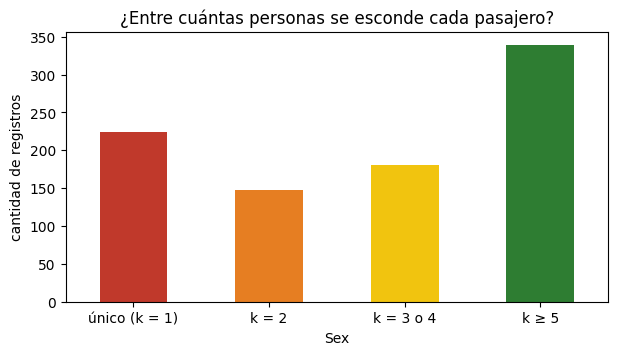

In [ ]:
def tamano_de_grupo(df, cuasi):
    # Para cada registro: cuántos registros comparten su combinación de cuasi-identificadores.
    return df.groupby(cuasi, dropna=False, observed=True)[cuasi[0]].transform("size")

def resumen_k(df, cuasi, titulo):
    k = tamano_de_grupo(df, cuasi)
    tramos = pd.cut(k, bins=[0, 1, 2, 4, np.inf], labels=["único (k = 1)", "k = 2", "k = 3 o 4", "k ≥ 5"])
    print(f"{titulo}: k mínimo = {k.min()} · registros únicos = {(k == 1).sum()} ({(k == 1).mean():.1%})")
    return tramos.value_counts().sort_index()

cuasi = ["Sex", "Age", "Pclass", "Embarked"]
antes = resumen_k(sin_identificadores, cuasi, "Datos sin nombre")

antes.plot.bar(color=["#c0392b", "#e67e22", "#f1c40f", "#2e7d32"], figsize=(7, 3.5), rot=0)
plt.ylabel("cantidad de registros")
plt.title("¿Entre cuántas personas se esconde cada pasajero?")
plt.show()

Una parte importante de los registros es **única**: aunque no tengan nombre, se pueden identificar.

### Cómo se protege: generalización y supresión

- **Generalizar:** reemplazar un valor preciso por un rango. La edad exacta pasa a ser un tramo de edad.
- **Suprimir:** eliminar (o dejar en blanco) los registros que siguen siendo únicos después de generalizar.

Buscamos que cada combinación aparezca al menos **k = 5** veces.

In [ ]:
generalizado = sin_identificadores.copy()
generalizado["Age"] = pd.cut(generalizado["Age"], bins=[0, 17, 34, 54, 100],
                             labels=["0-17", "18-34", "35-54", "55+"])
despues = resumen_k(generalizado, cuasi, "Edad en tramos")

# Supresión: se eliminan los registros que siguen en grupos de menos de 5
K = 5
k_gen = tamano_de_grupo(generalizado, cuasi)
anonimo = generalizado[k_gen >= K]
print(f"\nCon supresión (k ≥ {K}): se eliminan {len(generalizado) - len(anonimo)} registros "
      f"({1 - len(anonimo) / len(generalizado):.1%}); k mínimo = {tamano_de_grupo(anonimo, cuasi).min()}")

pd.DataFrame({"original": antes, "edad en tramos": despues})

Edad en tramos: k mínimo = 1 · registros únicos = 14 (1.6%)

Con supresión (k ≥ 5): se eliminan 62 registros (7.0%); k mínimo = 5


,original,edad en tramos
Sex,,
único (k = 1),224,14
k = 2,148,10
k = 3 o 4,180,38
k ≥ 5,339,829


### ¿Cuánto se perdió?

La protección tiene un costo: perdimos la edad exacta y algunos registros. Comprobemos si las conclusiones principales se mantienen, comparando la tasa de supervivencia por clase y sexo.

In [ ]:
comparacion = pd.DataFrame({
    "original": titanic.groupby(["Pclass", "Sex"])["Survived"].mean(),
    f"anonimizado (k ≥ {K})": anonimo.groupby(["Pclass", "Sex"])["Survived"].mean(),
}).round(3)
comparacion

original  anonimizado (k ≥ 5)
Pclass Sex                                  
1      female     0.968                0.962
       male       0.369                0.350
2      female     0.921                0.922
       male       0.157                0.146
3      female     0.500                0.489
       male       0.135                0.142

Las conclusiones se mantienen: las mujeres y los pasajeros de primera clase tuvieron mucha más probabilidad de sobrevivir. **Una buena anonimización protege a las personas y conserva lo que se quiere analizar.**

### Un límite del k-anonimato

Si en un grupo de 5 personas **todas** comparten el atributo sensible (por ejemplo, ninguna sobrevivió), sabiendo que alguien está en ese grupo se deduce igual el dato. Por eso existen criterios más exigentes, como la **l-diversidad**: en cada grupo debe haber al menos l valores distintos del atributo sensible.

In [ ]:
diversidad = anonimo.groupby(cuasi, dropna=False, observed=True)["Survived"].nunique()
print(f"Grupos en los que todos tienen el mismo resultado: {(diversidad == 1).sum()} de {len(diversidad)}")

Grupos en los que todos tienen el mismo resultado: 5 de 40


---
# Ejercicio 4 · Seudonimizar no es anonimizar, y privacidad contra utilidad

### 4.a. El hash de un DNI se puede revertir

Una práctica muy común es reemplazar el DNI o el CUIT por su **hash**, una función que lo transforma en un código ilegible. Parece seguro, pero hay un problema: los DNI posibles son pocos, unos decenas de millones. Un atacante puede calcular el hash de **todos** los DNI posibles y buscar coincidencias.

Simulamos una base de 1.000 clientes con DNI ficticios.

In [ ]:
import hashlib, hmac, secrets, time

rng = np.random.default_rng(42)
clientes = pd.DataFrame({
    "dni": rng.integers(20_000_000, 45_000_000, 1000),
    "ingreso": rng.lognormal(mean=13.5, sigma=0.5, size=1000).round(-3),
    "deuda": rng.lognormal(mean=12.5, sigma=1.0, size=1000).round(-3),
})

def hash_simple(dni):
    return hashlib.sha256(str(dni).encode()).hexdigest()

clientes["dni_hash"] = clientes["dni"].apply(hash_simple)
clientes[["dni", "dni_hash", "ingreso"]].head(3)

,dni,dni_hash,ingreso
0,22231273,b803791fa0763054fd15bf065801c228dfbddc530b37ff...,764000.0
1,39348901,f48e338819fbacc0bde9d9dc57b611ccafed72f060c17d...,975000.0
2,36364287,1a4212b5a38925f58ae4c7589ff5fbb802f6d92c32784b...,709000.0


El atacante recibe solo la columna `dni_hash`. Probamos cuánto tarda en calcular el hash de un millón de DNI candidatos:

In [ ]:
objetivo = clientes.loc[0, "dni_hash"]            # el hash que el atacante quiere revertir
inicio_rango = clientes.loc[0, "dni"] - 500_000   # le damos un rango de un millón de candidatos

t0 = time.time()
encontrado = None
for candidato in range(inicio_rango, inicio_rango + 1_000_000):
    if hash_simple(candidato) == objetivo:
        encontrado = candidato
        break
segundos = time.time() - t0

print(f"DNI encontrado: {encontrado} (real: {clientes.loc[0, 'dni']}) en {segundos:.1f} segundos")
total = 25_000_000 / (encontrado - inicio_rango + 1) * segundos     # extrapolación a todos los DNI posibles
print(f"Recorrer los 25 millones de DNI posibles tomaría unos {total / 60:.1f} minutos en esta computadora")

DNI encontrado: 22231273 (real: 22231273) en 0.6 segundos
Recorrer los 25 millones de DNI posibles tomaría unos 0.5 minutos en esta computadora


En segundos o, a lo sumo, en pocos minutos se revierte cualquier DNI, y con hardware especializado es todavía más rápido. El hash simple es una **seudonimización**: reemplaza el dato, pero la persona sigue siendo identificable.

**La solución:** un hash **con clave secreta** (HMAC). Sin la clave, el atacante no puede calcular los hashes de los candidatos. La clave se guarda aparte, como la tabla de correspondencia.

In [ ]:
CLAVE_SECRETA = secrets.token_bytes(32)          # se guarda en un lugar seguro, nunca junto a los datos

def hash_con_clave(dni):
    return hmac.new(CLAVE_SECRETA, str(dni).encode(), hashlib.sha256).hexdigest()

clientes["dni_seudonimo"] = clientes["dni"].apply(hash_con_clave)
print("Hash simple del DNI:  ", hash_simple(clientes.loc[0, "dni"])[:32], "…")
print("Hash con clave secreta:", clientes.loc[0, "dni_seudonimo"][:32], "…")

Hash simple del DNI:   b803791fa0763054fd15bf065801c228 …
Hash con clave secreta: b843b7f5a19c18edd80aaf7a47b971de …


**Importante:** aun con clave, esto sigue siendo **seudonimización**. Quien tenga la clave puede volver a la persona. Por eso los datos seudonimizados siguen siendo datos personales y se protegen como tales (así lo establece expresamente, por ejemplo, el Reglamento General de Protección de Datos europeo). Son anónimos solo si se destruye la clave y no hay otra forma razonable de reidentificar.

### 4.b. Privacidad contra utilidad: números falsos o ruido controlado

En el ejercicio 1, `fake_decimal_numbers` reemplazó la tarifa por números al azar. Comparemos tres maneras de proteger la tarifa y veamos qué pasa con un análisis simple: la **tarifa promedio por clase**.

- **Original:** sin protección.
- **Números falsos** (`anonymizedf`): cada valor se reemplaza por uno al azar.
- **Ruido controlado:** a cada tarifa se le suma un error aleatorio de media cero. Cada valor individual cambia, pero los promedios se mantienen. Es la idea detrás de la **privacidad diferencial**, que usan, por ejemplo, algunas oficinas de estadística para publicar resultados censales.

In [ ]:
tarifas = titanic[["Pclass", "Fare"]].copy()
tarifas["Fare_falsa"] = archivo_1["Fake_Fare"].to_numpy()                  # la columna que generó anonymizedf
tarifas["Fare_ruido"] = tarifas["Fare"] + rng.laplace(0, 15, len(tarifas))  # ruido de Laplace, escala 15

promedios = tarifas.groupby("Pclass")[["Fare", "Fare_falsa", "Fare_ruido"]].mean().round(1)
promedios.columns = ["original", "números falsos", "con ruido"]
promedios

,original,números falsos,con ruido
Pclass,,,
1,84.2,259.3,83.2
2,20.7,241.2,19.4
3,13.7,272.4,13.4


In [ ]:
tarifas

,Pclass,Fare,Fare_falsa,Fare_ruido
0,3,7.2500,207.00,19.664986
1,1,71.2833,80.38,67.059066
2,3,7.9250,278.95,-47.532045
3,1,53.1000,82.48,53.394920
4,3,8.0500,396.70,8.267270
...,...,...,...,...
886,2,13.0000,83.84,18.741063
887,1,30.0000,23.43,26.750517
888,3,23.4500,434.78,5.803748
889,1,30.0000,23.43,30.885503


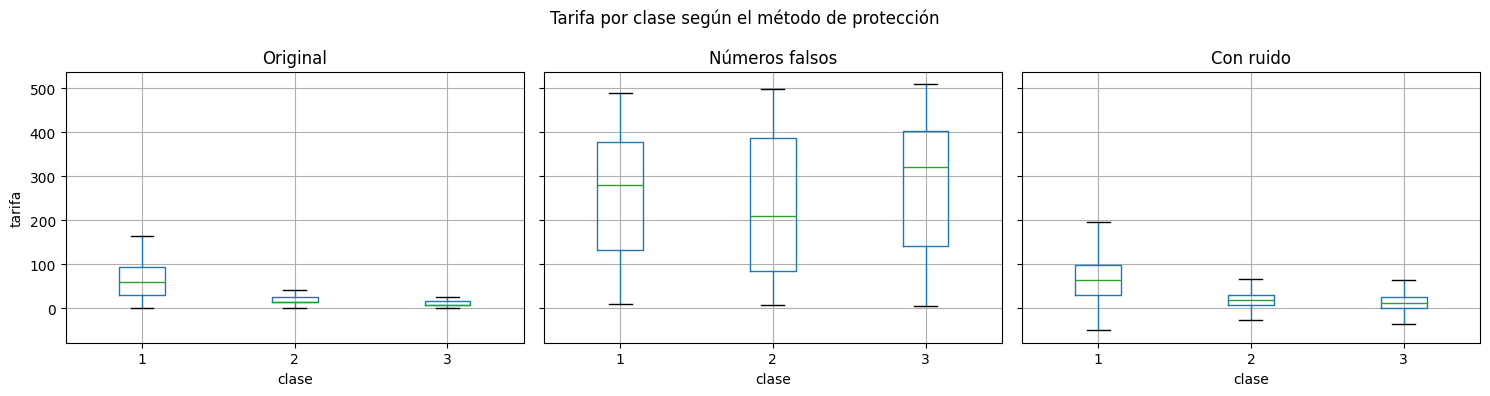

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col, titulo in zip(axes, ["Fare", "Fare_falsa", "Fare_ruido"], ["Original", "Números falsos", "Con ruido"]):
    tarifas.boxplot(column=col, by="Pclass", ax=ax, showfliers=False)
    ax.set_title(titulo); ax.set_xlabel("clase")
axes[0].set_ylabel("tarifa")
plt.suptitle("Tarifa por clase según el método de protección")
plt.tight_layout()
plt.show()

**¿Qué se ve?**

- Con **números falsos**, la relación entre la clase y la tarifa **desaparece**: las tres clases quedan con tarifas parecidas. Cualquier conclusión que saquemos de esa columna es falsa.
- Con **ruido controlado**, cada tarifa individual ya no es exacta (no se puede saber cuánto pagó una persona puntual), pero los **promedios y la relación entre clase y tarifa se conservan**.

¿Cuánto ruido conviene agregar? Es un equilibrio: más ruido es más privacidad y menos precisión.

In [ ]:
filas = []
for escala in [1, 5, 15, 50, 150]:
    ruido = tarifas["Fare"] + rng.laplace(0, escala, len(tarifas))
    filas.append({
        "escala del ruido": escala,
        "error medio por persona": (ruido - tarifas["Fare"]).abs().mean(),
        "error en el promedio por clase": (ruido.groupby(tarifas["Pclass"]).mean()
                                           - tarifas.groupby("Pclass")["Fare"].mean()).abs().mean(),
    })
pd.DataFrame(filas).set_index("escala del ruido").round(2)

,error medio por persona,error en el promedio por clase
escala del ruido,,
1,0.99,0.07
5,4.82,0.36
15,15.10,1.04
50,47.76,3.83
150,155.32,3.08


El error **individual** crece con el ruido (más privacidad), mientras que el error en los **promedios** se mantiene chico, porque los errores se compensan al promediar muchas personas. Con muchos datos se puede proteger mucho a cada persona sin perder las conclusiones agregadas, que es lo que suele interesar.

---
# Responsabilidad ética en el uso de datos

Las técnicas de anonimización son herramientas. La responsabilidad empieza antes de usarlas, con preguntas como **qué datos necesito, para qué, con qué autorización y qué consecuencias puede tener mi análisis para las personas**.

### El marco legal en la Argentina

La **Ley 25.326 de Protección de los Datos Personales** regula el tratamiento de datos de personas humanas y jurídicas. Su autoridad de aplicación es la **Agencia de Acceso a la Información Pública (AAIP)**. Algunos puntos clave:

| Principio | Qué establece | En la práctica |
|---|---|---|
| **Consentimiento** (art. 5) | Tratar datos requiere el consentimiento libre, expreso e informado del titular, salvo excepciones legales | ¿Los clientes aceptaron que sus datos se usen para este análisis? |
| **Finalidad y calidad** (art. 4) | Los datos deben ser ciertos, adecuados, pertinentes y no excesivos para la finalidad con la que se obtuvieron, y no pueden usarse para fines incompatibles | Datos recolectados para facturar no se reutilizan sin más para otro fin |
| **Datos sensibles** (arts. 2 y 7) | Origen racial o étnico, opiniones políticas, convicciones religiosas, filosóficas o morales, afiliación sindical, salud y vida sexual tienen protección especial | Evitarlos salvo que sean imprescindibles y estén autorizados |
| **Seguridad y confidencialidad** (arts. 9 y 10) | Quien trata datos debe adoptar medidas de seguridad y guardar secreto profesional | Acceso restringido, cifrado, no compartir planillas por canales inseguros |
| **Derechos del titular** (arts. 14 a 16) | Acceso, rectificación, actualización y supresión de sus datos | Tener un procedimiento para responder estos pedidos |
| **Disociación** (art. 2) | Tratar los datos de modo que la información no pueda asociarse a una persona determinada o determinable | Es lo que buscamos al anonimizar |

Para el trabajo con datos estadísticos oficiales rige además el **secreto estadístico** (Ley 17.622): la información de personas y empresas solo se publica agregada, de modo que no pueda individualizarse a nadie.

### Más allá de la ley: casos que enseñan

- **AOL (2006):** la empresa publicó millones de búsquedas "anonimizadas", con los usuarios reemplazados por números. Periodistas del *New York Times* identificaron a una usuaria a partir de sus propias búsquedas.
- **Netflix Prize (2006-2008):** Netflix publicó calificaciones de películas sin nombres para un concurso. Investigadores (Narayanan y Shmatikov) mostraron que cruzándolas con reseñas públicas de otro sitio se podía reidentificar a los usuarios.
- **Sesgos en modelos:** un modelo de scoring crediticio que no usa el sexo ni el origen puede igualmente discriminar a través de variables correlacionadas, como el barrio. **Sacar la variable sensible no garantiza un modelo justo**: hay que medir los resultados por grupo.

### Responsabilidades del profesional

1. **Minimizar:** usar solo los datos necesarios para la pregunta que se quiere responder.
2. **Anonimizar o seudonimizar lo antes posible**, y guardar la tabla de correspondencia o la clave por separado y con acceso restringido.
3. **Evaluar el riesgo de reidentificación** antes de publicar o compartir: cuasi-identificadores, registros únicos, cruces con otras fuentes.
4. **Cuidar la utilidad:** elegir técnicas que no inventen conclusiones falsas.
5. **No cargar datos personales ni confidenciales en herramientas externas**, como servicios de IA generativa, sin autorización ni garantías sobre su tratamiento. Para los contadores, esto se suma al **secreto profesional**.
6. **Revisar los efectos del análisis:** ¿el modelo perjudica sistemáticamente a algún grupo? ¿Las personas podrían verse afectadas por decisiones automatizadas que no pueden cuestionar?
7. **Documentar** qué datos se usaron, de dónde vienen, qué transformaciones se aplicaron y con qué autorización.

### Para discutir en clase

1. Un estudio contable quiere usar la base de sus clientes para entrenar un modelo que detecte riesgo fiscal y publicar los resultados en un congreso. ¿Qué debería hacer antes?
2. Un banco elimina el sexo y la edad de su modelo de scoring para "no discriminar". ¿Alcanza? ¿Cómo lo verificarían?
3. Para la tesis, ¿qué datos personales van a usar? ¿Cómo los van a proteger, y qué van a escribir en la sección de aspectos éticos?

### Para practicar

1. En el ejercicio 3, agreguen `SibSp` y `Parch` a los cuasi-identificadores. ¿Qué pasa con el k-anonimato? ¿Qué generalización propondrían?
2. Busquen el valor de k más alto que se puede alcanzar eliminando menos del 10 % de los registros.
3. En el ejercicio 4.b, repitan la comparación para la tarifa promedio de los sobrevivientes y de los no sobrevivientes. ¿Qué método conserva la diferencia?